<a href="https://colab.research.google.com/github/FadhilTaufiqurrachman/Machine-Learning/blob/main/244107020090_Fadhil_Taufiqurrachman_P7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Jobsheet 7 - Regresi

NIM : 244107020090

Nama : Fadhil Taufiqurrachman

Kelas : TI 3G

No Absen : 06

Mata Kuliah : Pembelajaran Mesin

### Praktikum 1

Langkah 1: Persiapan Data

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
BASE_PATH = '/content/drive/MyDrive/Education/Current Semester College File /Machine Learning/'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Langkah 2: Import Library

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
from sklearn.metrics import r2_score

Langkah 3: Baca Data

In [ ]:
data = pd.read_csv(BASE_PATH + 'dataset.csv')

Langkah 4: Pemahaman Terhadap Data

In [ ]:
# Menampilkan 5 baris pertama untuk melihat bentuk data
print("Data Awal:")
display(data.head())

# Mengecek jumlah baris dan kolom
print("\nUkuran Data:", data.shape)

# Mengecek tipe data dan missing value
print("\nInformasi Data:")
data.info()

# Melihat rangkuman statistik dari kolom numerik
print("\nDeskripsi Statistik:")
display(data.describe())

Data Awal:


,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\r\nCobbborough,...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\r\nPort Jason, OH 22070-...",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\r\nPort Jacobville, PR...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092



Ukuran Data: (500, 8)

Informasi Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB

Deskripsi Statistik:


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


Langkah 5: Visualisasi Data

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:2100: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


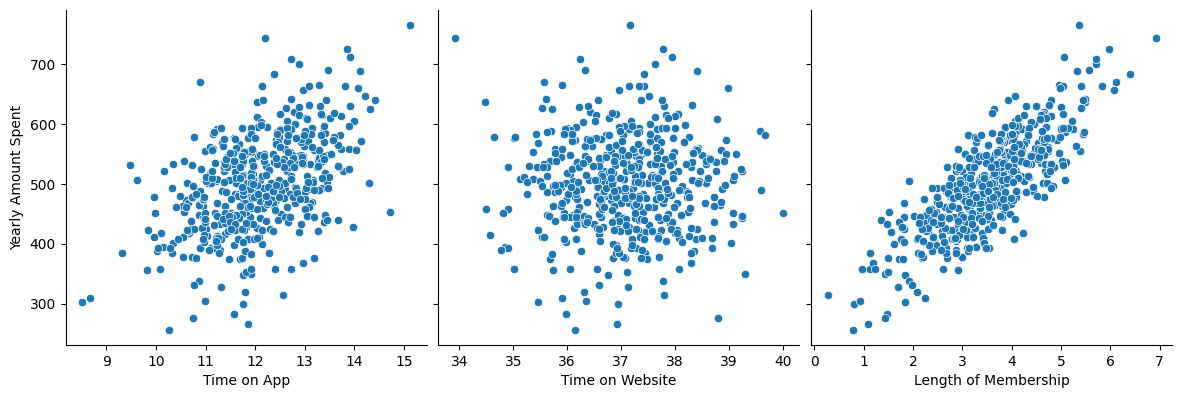

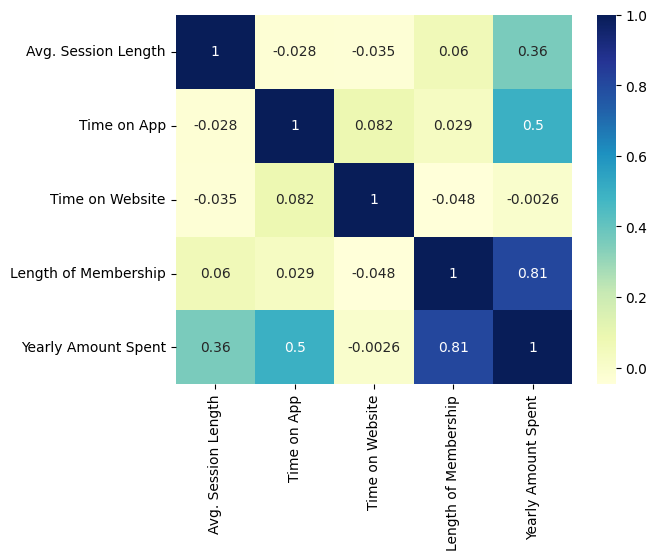

In [ ]:
sns.pairplot(data, x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', size=4, aspect=1, kind='scatter')
plt.show()

# Heatmap untuk melihat matriks korelasi berupa angka secara spesifik
numeric_data = data.select_dtypes(include=[np.number])
sns.heatmap(numeric_data.corr(), cmap="YlGnBu", annot=True)
plt.show()

Langkah 6: Regresi Linier

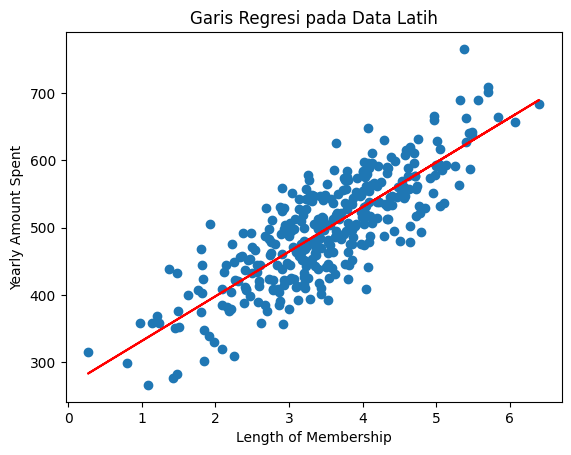

In [ ]:
# Mendefinisikan variabel bebas (X) dan target (y)
X = data['Length of Membership']
y = data['Yearly Amount Spent']

# Membagi data latih (70%) dan data uji (30%)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

# Training model menggunakan statsmodels
X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

# Visualisasi garis regresi pada data latih
plt.scatter(X_train, y_train)
plt.plot(X_train, 265.2483 + 66.3015*X_train, 'r')
plt.title('Garis Regresi pada Data Latih')
plt.xlabel('Length of Membership')
plt.ylabel('Yearly Amount Spent')
plt.show()

Langkah 7: Analisis Residual

/tmp/ipykernel_1791/4212946386.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(res, bins=15)


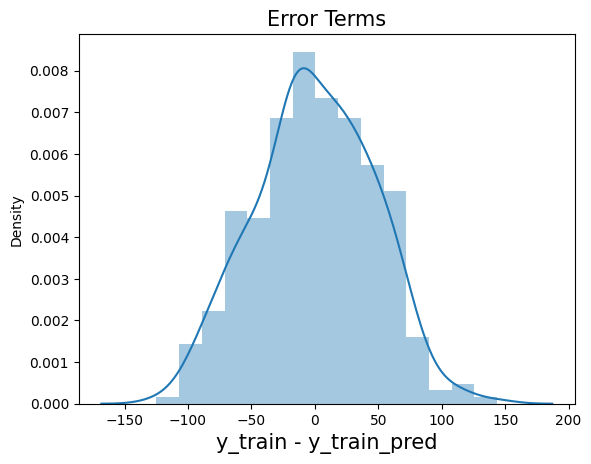

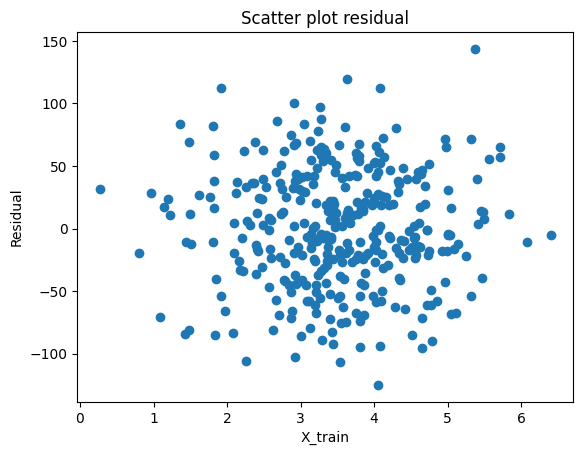

In [ ]:
# Melakukan prediksi terhadap data training
y_train_pred = lr.predict(X_train_sm)

# Menghitung residual (selisih nilai aktual dan prediksi)
res = (y_train - y_train_pred)

# Histogram residual untuk melihat distribusi error
fig = plt.figure()
sns.distplot(res, bins=15)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

# Scatter plot residual untuk melihat pola homoskedastisitas
plt.scatter(X_train, res)
plt.title('Scatter plot residual')
plt.xlabel('X_train')
plt.ylabel('Residual')
plt.show()

Langkah 8: Prediksi pada Data Uji dan Evaluasi Model

In [ ]:
# Menambahkan konstanta pada data uji
X_test_sm = sm.add_constant(X_test)

# Melakukan prediksi pada data uji
y_test_pred = lr.predict(X_test_sm)

# Menghitung R-squared
r_squared = r2_score(y_test, y_test_pred)
print("Nilai R-squared pada data uji:", r_squared)

Nilai R-squared pada data uji: 0.611948913768747


Langkah 9: Visualisasi Hasil

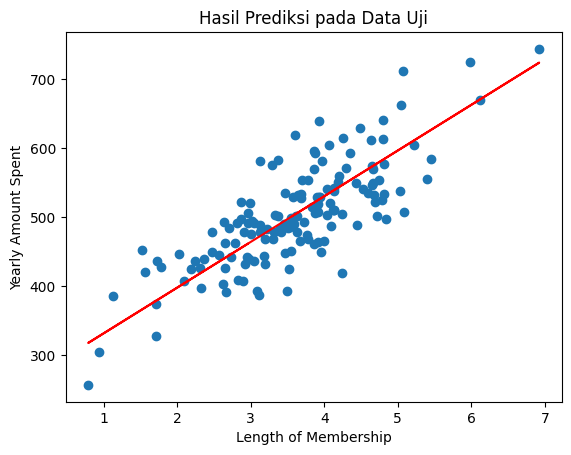

In [ ]:
# Memvisualisasikan sebaran data uji dengan garis prediksi merah
plt.scatter(X_test, y_test)
plt.plot(X_test, y_test_pred, 'r')
plt.title('Hasil Prediksi pada Data Uji')
plt.xlabel('Length of Membership')
plt.ylabel('Yearly Amount Spent')
plt.show()

Melalui tahapan Exploratory Data Analysis (EDA) menggunakan pairplot dan heatmap, teridentifikasi dengan jelas bahwa fitur Length of Membership memiliki koefisien korelasi linier tertinggi terhadap target Yearly Amount Spent. Saat model dilatih, algoritma Ordinary Least Squares (OLS) mampu menemukan garis best-fit optimal yang direpresentasikan dengan persamaan linear y = 265.2483 + 66.3015x. Model ini sangat valid dan memenuhi prasyarat regresi parametrik, dibuktikan oleh analisis residual di mana distribusi error membentuk kurva lonceng normal (berpusat di titik 0) serta scatter plot residual yang tersebar acak tanpa pola corong/mengelompok (mengindikasikan homoskedastisitas). Pada akhirnya, ketika diaplikasikan pada data uji, garis regresi merah menempel sangat baik mengikuti sebaran titik data testing aktual, membuktikan model berhasil menangkap pola utama tanpa mengalami overfitting.

### Praktikum 2

Langkah 1: Mengimpor Dataset

In [ ]:
dataset = pd.read_csv(BASE_PATH + 'Posisi_gaji.csv')

# Memilih kolom fitur (Tingkat Posisi) dan mengubahnya menjadi matriks 2D
X = dataset.iloc[:, 1:2].values
# Memilih kolom target (Gaji)
y = dataset.iloc[:, 2].values

Langkah 2: Feature Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler

# Inisialisasi scaler terpisah untuk X dan y
sc_X = StandardScaler()
sc_y = StandardScaler()

# Melakukan penskalaan dan transformasi
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))

Langkah 3: Fitting SVR ke Dataset

In [ ]:
# 4. Fitting SVR ke Dataset
from sklearn.svm import SVR

# Membuat objek model SVR dengan kernel RBF
regressor = SVR(kernel='rbf')

# Melatih (fitting) model ke data yang sudah disekalakan (X dan y)
regressor.fit(X, y.ravel()) # Menambahkan .ravel() karena fit membutuhkan array 1D

SVR()

Langkah 4: Visualisasi Hasil SVR

/tmp/ipykernel_1791/3960728127.py:1: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)


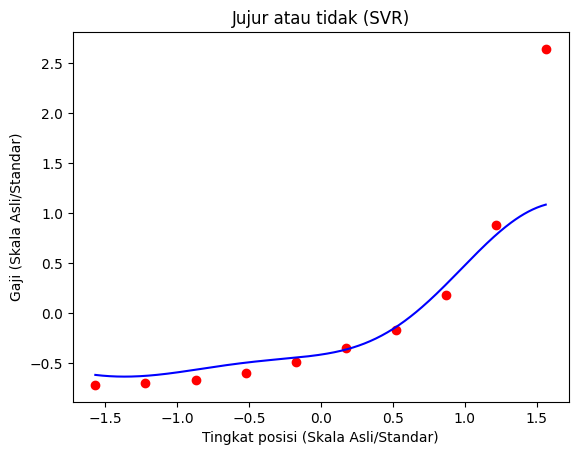

In [ ]:
X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)

plt.scatter(X, y, color='red')
plt.plot(X_grid, regressor.predict(X_grid), color='blue')

plt.title('Jujur atau tidak (SVR)')
plt.xlabel('Tingkat posisi (Skala Asli/Standar)')
plt.ylabel('Gaji (Skala Asli/Standar)')
plt.show()

Langkah 5: Prediksi Hasil

In [ ]:
tingkat_posisi_prediksi = np.array([[6.5]])

# Penskalaan fitur untuk data yang akan diprediksi menggunakan scaler X
tingkat_posisi_prediksi_scaled = sc_X.transform(tingkat_posisi_prediksi)

# Melakukan prediksi menggunakan model SVR
gaji_prediksi_scaled = regressor.predict(tingkat_posisi_prediksi_scaled)

# Kembalikan hasil prediksi ke skala aslinya menggunakan scaler y
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi_scaled.reshape(-1, 1))

Langkah 6: Menampilkan Hasil

In [ ]:
print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0][0])

Prediksi Gaji untuk Tingkat Posisi 6.5: 170370.02040650236


Langkah 7: Evaluasi Model SVR

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Menentukan data aktual dan data prediksi
y_actual = y
y_pred = regressor.predict(X)

# Menghitung metrik error
mae = mean_absolute_error(y_actual, y_pred)
mse = mean_squared_error(y_actual, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_actual, y_pred)

# Menampilkan hasil evaluasi
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.22299274095734414
MSE: 0.24839989293792014
RMSE: 0.4983973243687411
R-squared: 0.7516001070620798


Penerapan Support Vector Regression (SVR) dengan kernel Radial Basis Function (RBF) pada dataset Posisi_gaji.csv menunjukkan bahwa model ini cukup andal dalam menangkap hubungan non-linear antara hierarki jabatan dan tingkat kompensasi. Keberhasilan SVR sangat bergantung pada langkah prapemrosesan Feature Scaling (Standardisasi), karena tanpa proses tersebut algoritma akan bias terhadap nilai fitur bergaji ratusan ribu dibandingkan nilai posisi yang hanya berkisar satuan belasan. Visualisasi kurva biru (hasil prediksi) yang mulus membuktikan bahwa model mampu mengikuti pola melengkung sebaran titik merah (data riil) secara cukup baik, menghindari model garis lurus yang kaku pada regresi linier biasa. Ketika digunakan untuk mengestimasi, model memprediksikan bahwa figur di posisi mid-level 6.5 diproyeksikan mendapatkan kompensasi sebesar $170,370.02, sebuah nilai yang logis dan konsisten dengan tren data latih. Evaluasi kuantitatif turut mendukung kualitas model, dibuktikan oleh skor R-squared sekitar 0.75 yang mengindikasikan 75% variasi data dapat dijelaskan secara efektif, ditunjang oleh angka error (MAE, MSE, RMSE) yang relatif terjaga dalam skala datanya.